**the NIH labels are weak labels derived from radiology-report text rather than manually verified labels for every image, so that will become an important limitation of the project**

-------------------------------------------

# NIH ChestX-ray14 Multi-label Classification

## Project Goal

The goal of this project is to build a deep learning workflow for multi-label thoracic disease classification using the NIH ChestX-ray14 dataset and PyTorch.

The project will begin with dataset inspection and exploratory analysis before moving into patient-level data splitting, image preprocessing, PyTorch datasets and dataloaders, transfer learning, model evaluation, threshold selection, error analysis, explainability, and assessment of clinical usefulness.

## Data Source

This project uses the **NIH ChestX-ray14** dataset, a large publicly available chest X-ray dataset released by the National Institutes of Health Clinical Center.

The dataset contains:

- **112,120 frontal chest X-ray images**
- **30,805 patients**
- labels for **14 thoracic disease categories**
- patient and image metadata
- disease labels derived from associated radiology reports

The dataset will be used for multi-label classification, meaning that a single chest X-ray may contain more than one labeled finding.

### Dataset Citation

Wang, X., Peng, Y., Lu, L., Lu, Z., Bagheri, M., & Summers, R. M. (2017).  
*ChestX-ray8: Hospital-scale chest X-ray database and benchmarks on weakly-supervised classification and localization of common thorax diseases.*  
Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (CVPR), 2097–2106.

The NIH ChestX-ray14 dataset is an expanded release of the dataset described in this publication.

---------------------------------------------------

## Initial Dataset Inspection

Begin by reviewing the dataset dimensions, column structure, data types, and missingness before any cleaning or feature engineering.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np

In [2]:
# Use a relative path so the notebook remains portable within the repository.
data_dir = Path("../data")

df = pd.read_csv(data_dir / "Data_Entry_2017_v2020.csv")

df.head()

,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Sex,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y]
0,00000001_000.png,Cardiomegaly,0,1,57,M,PA,2682,2749,0.143,0.143
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,0.143
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,0.168
3,00000002_000.png,No Finding,0,2,80,M,PA,2500,2048,0.171,0.171
4,00000003_001.png,Hernia,0,3,74,F,PA,2500,2048,0.168,0.168


In [3]:
df.shape

(112120, 11)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 112120 entries, 0 to 112119
Data columns (total 11 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Image Index                  112120 non-null  str    
 1   Finding Labels               112120 non-null  str    
 2   Follow-up #                  112120 non-null  int64  
 3   Patient ID                   112120 non-null  int64  
 4   Patient Age                  112120 non-null  int64  
 5   Patient Sex                  112120 non-null  str    
 6   View Position                112120 non-null  str    
 7   OriginalImage[Width          112120 non-null  int64  
 8   Height]                      112120 non-null  int64  
 9   OriginalImagePixelSpacing[x  112120 non-null  float64
 10  y]                           112120 non-null  float64
dtypes: float64(2), int64(5), str(4)
memory usage: 9.4 MB


In [5]:
df.describe(include='all')

,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Sex,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y]
count,112120,112120,112120.000000,112120.000000,112120.000000,112120,112120,112120.000000,112120.000000,112120.000000,112120.000000
unique,112120,836,NaN,NaN,NaN,2,2,NaN,NaN,NaN,NaN
top,00000001_000.png,No Finding,NaN,NaN,NaN,M,PA,NaN,NaN,NaN,NaN
freq,1,60361,NaN,NaN,NaN,63340,67310,NaN,NaN,NaN,NaN
mean,NaN,NaN,8.573751,14346.381743,46.626365,NaN,NaN,2646.078844,2486.438842,0.155649,0.155649
std,NaN,NaN,15.406320,8403.876972,16.602680,NaN,NaN,341.246429,401.268227,0.016174,0.016174
min,NaN,NaN,0.000000,1.000000,0.000000,NaN,NaN,1143.000000,966.000000,0.115000,0.115000
25%,NaN,NaN,0.000000,7310.750000,34.000000,NaN,NaN,2500.000000,2048.000000,0.143000,0.143000
50%,NaN,NaN,3.000000,13993.000000,49.000000,NaN,NaN,2518.000000,2544.000000,0.143000,0.143000
75%,NaN,NaN,10.000000,20673.000000,59.000000,NaN,NaN,2992.000000,2991.000000,0.168000,0.168000


In [6]:
df.columns.tolist()

['Image Index',
 'Finding Labels',
 'Follow-up #',
 'Patient ID',
 'Patient Age',
 'Patient Sex',
 'View Position',
 'OriginalImage[Width',
 'Height]',
 'OriginalImagePixelSpacing[x',
 'y]']

In [7]:
df = df.rename(columns={
    "Image Index": "image_index",
    "Finding Labels": "finding_labels",
    "Follow-up #": "follow_up",
    "Patient ID": "patient_id",
    "Patient Age": "patient_age",
    "Patient Sex": "patient_sex",
    "View Position": "view_position",
    "OriginalImage[Width": "image_width",
    "Height]": "image_height",
    "OriginalImagePixelSpacing[x": "pixel_spacing_x",
    "y]": "pixel_spacing_y"
})

df.head()

,image_index,finding_labels,follow_up,patient_id,patient_age,patient_sex,view_position,image_width,image_height,pixel_spacing_x,pixel_spacing_y
0,00000001_000.png,Cardiomegaly,0,1,57,M,PA,2682,2749,0.143,0.143
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,0.143
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,0.168
3,00000002_000.png,No Finding,0,2,80,M,PA,2500,2048,0.171,0.171
4,00000003_001.png,Hernia,0,3,74,F,PA,2500,2048,0.168,0.168


## Finding Label Structure

The dataset uses multi-label annotations, meaning a single chest X-ray may contain more than one finding. 

The label structure and prevalence of individual findings are examined before modeling to understand class imbalance and disease co-occurrence.

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df["image_index"].duplicated().sum()

np.int64(0)

In [10]:
df.nunique().sort_values(ascending=False)

image_index        112120
patient_id          30805
image_height         1137
image_width           904
finding_labels        836
follow_up             184
patient_age            96
pixel_spacing_x        23
pixel_spacing_y        23
view_position           2
patient_sex             2
dtype: int64

In [11]:
df['patient_sex'].value_counts()

patient_sex
M    63340
F    48780
Name: count, dtype: int64

In [12]:
df["view_position"].value_counts()

view_position
PA    67310
AP    44810
Name: count, dtype: int64

## Patient-Level Structure

Because individual patients may have multiple chest X-rays, the distribution of images per patient is examined before label analysis and model splitting. 

Patient-level separation will be necessary later to prevent images from the same patient appearing in both training and evaluation sets.

In [13]:
images_per_patient = df.groupby("patient_id").size()

images_per_patient.describe()

count    30805.000000
mean         3.639669
std          7.266734
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max        184.000000
dtype: float64

In [14]:
images_per_patient.value_counts().sort_index().head(20)

1     17503
2      4113
3      2100
4      1330
5       938
6       787
7       608
8       494
9       387
10      320
11      281
12      235
13      165
14      181
15      121
16      120
17       91
18       77
19       77
20       74
Name: count, dtype: int64

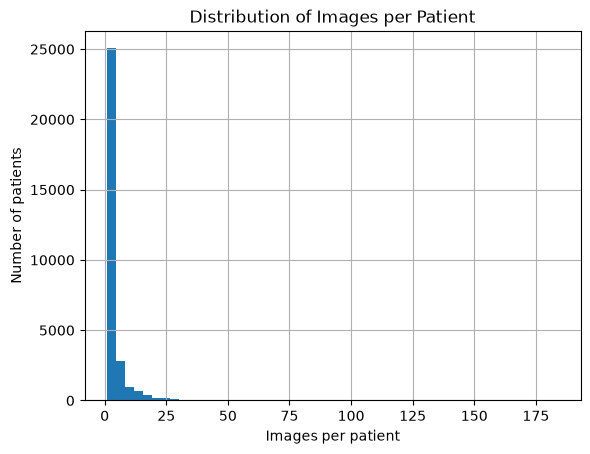

In [15]:
import matplotlib.pyplot as plt

images_per_patient.hist(bins=50)

plt.xlabel("Images per patient")
plt.ylabel('Number of patients')
plt.title('Distribution of Images per Patient')
plt.show()

Most patients have relatively few images, with a median of one image per patient and 75% of patients having three or fewer images. However, a small number of patients have many repeated examinations, with as many as 184 images for a single patient.

Because multiple images can belong to the same patient, train, validation, and test sets must be separated at the patient level to prevent information leakage between model development and evaluation.

## Finding Label Structure

The dataset uses multi-label annotations, meaning a single chest X-ray may contain more than one finding. The label structure and prevalence of individual findings are examined before modeling to understand class imbalance and disease co-occurrence.

In [16]:
df["finding_labels"].value_counts().head(10)

finding_labels
No Finding                  60361
Infiltration                 9547
Atelectasis                  4215
Effusion                     3955
Nodule                       2705
Pneumothorax                 2194
Mass                         2139
Effusion|Infiltration        1603
Atelectasis|Infiltration     1350
Consolidation                1310
Name: count, dtype: int64

In [17]:
# Extract every unique finding represented in the pipe-delimited label strings
all_labels = sorted({
    label
    for labels in df["finding_labels"].str.split("|")
    for label in labels
})

all_labels

['Atelectasis',
 'Cardiomegaly',
 'Consolidation',
 'Edema',
 'Effusion',
 'Emphysema',
 'Fibrosis',
 'Hernia',
 'Infiltration',
 'Mass',
 'No Finding',
 'Nodule',
 'Pleural_Thickening',
 'Pneumonia',
 'Pneumothorax']

In [18]:
for label in all_labels:
    df[label] = df["finding_labels"].str.contains(label, regex=False).astype(int)

In [19]:
label_summary = pd.DataFrame({
    "count": df[all_labels].sum(),
    "percent": df[all_labels].mean() * 100
}).sort_values("count", ascending=False)

label_summary = label_summary.round({"percent": 2})

label_summary


,count,percent
No Finding,60361,53.84
Infiltration,19894,17.74
Effusion,13317,11.88
Atelectasis,11559,10.31
Nodule,6331,5.65
Mass,5782,5.16
Pneumothorax,5302,4.73
Consolidation,4667,4.16
Pleural_Thickening,3385,3.02
Cardiomegaly,2776,2.48


In [20]:
df["num_findings"] = df[all_labels].sum(axis=1)
df["num_findings"].value_counts().sort_index()

num_findings
1    91324
2    14306
3     4856
4     1247
5      301
6       67
7       16
8        1
9        2
Name: count, dtype: int64

The label distribution is highly imbalanced. More than half of the images are labeled `No Finding`, while several individual abnormalities occur in fewer than 3% of images. The rarest finding, `Hernia`, appears in only 0.2% of the dataset.

Most images contain a single label, although multi-label cases are common enough to require a true multi-label modeling approach rather than treating the problem as mutually exclusive classification.

This imbalance will need to be considered when selecting evaluation metrics and training strategies.

In [23]:
# Exclude "No Finding" and count how often each pair of disease labels appears together.
disease_labels = [label for label in all_labels if label != "No Finding"]

cooccurrence = df[disease_labels].T.dot(df[disease_labels])

cooccurrence

,Atelectasis,Cardiomegaly,Consolidation,Edema,Effusion,Emphysema,Fibrosis,Hernia,Infiltration,Mass,Nodule,Pleural_Thickening,Pneumonia,Pneumothorax
Atelectasis,11559,370,1223,221,3275,424,220,40,3264,739,590,496,262,774
Cardiomegaly,370,2776,169,127,1063,44,52,7,587,102,108,111,41,49
Consolidation,1223,169,4667,162,1287,103,79,4,1221,610,428,251,123,223
Edema,221,127,162,2303,593,30,9,3,981,129,131,64,340,33
Effusion,3275,1063,1287,593,13317,359,188,21,4000,1254,912,849,269,996
Emphysema,424,44,103,30,359,2516,36,4,449,215,115,151,23,747
Fibrosis,220,52,79,9,188,36,1686,8,345,117,166,176,11,80
Hernia,40,7,4,3,21,4,8,227,33,25,10,8,3,9
Infiltration,3264,587,1221,981,4000,449,345,33,19894,1159,1546,750,605,946
Mass,739,102,610,129,1254,215,117,25,1159,5782,906,452,71,431


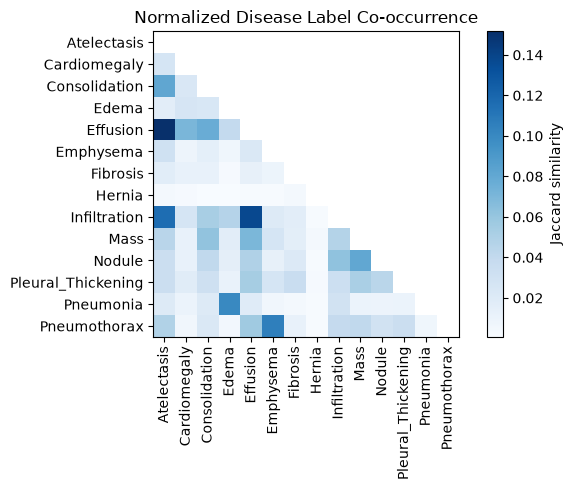

In [26]:
# Normalize pairwise overlap so common findings do not dominate the comparison.
label_counts = df[disease_labels].sum().to_numpy()
cooccurrence_array = cooccurrence.to_numpy()

union = (
    label_counts[:, None]
    + label_counts[None, :]
    - cooccurrence_array
)

jaccard = cooccurrence_array / union

# The matrix is symmetric, so display each disease pair only once.
mask = np.triu(np.ones_like(jaccard, dtype=bool), k=0)
jaccard_masked = np.ma.masked_where(mask, jaccard)

fig, ax = plt.subplots(figsize=(7, 5))

im = ax.imshow(jaccard_masked, cmap="Blues")

ax.set_xticks(range(len(disease_labels)))
ax.set_yticks(range(len(disease_labels)))
ax.set_xticklabels(disease_labels, rotation=90)
ax.set_yticklabels(disease_labels)

fig.colorbar(im, ax=ax, label="Jaccard similarity")
ax.set_title("Normalized Disease Label Co-occurrence")

plt.tight_layout()
plt.show()

Several findings show meaningful overlap rather than occurring independently. The strongest normalized co-occurrence was observed between Effusion and Atelectasis, followed by Infiltration with Effusion and Atelectasis. Other notable relationships included Pneumothorax with Emphysema and Nodule with Mass.

These patterns reinforce the multi-label nature of the dataset, since clinically related findings may appear together on the same image.

## Image-Level EDA

The metadata describes the patients, acquisition characteristics, and disease labels, but the model will ultimately learn from the chest X-ray images themselves. Before defining preprocessing or PyTorch transforms, the image files should be inspected directly to understand their dimensions, intensity range, view differences, and overall visual quality.

In [30]:
from PIL import Image

image_dir = data_dir / "images"

image_files = list(image_dir.glob("*.png"))

len(image_files)

10000

In [31]:
available_images = {path.name for path in image_files}

image_df = df[df["image_index"].isin(available_images)].copy()

image_df.shape

(10000, 27)

In [33]:
sample_path = image_dir / image_df.iloc[0]["image_index"]

image = Image.open(sample_path)
image_array = np.array(image)

print("Filename:", sample_path.name)
print("Shape", image_array.shape)
print("Data type:", image_array.dtype)
print("Min pixel value:", image_array.min())
print("Max pixel value:", image_array.max())

Filename: 00006585_007.png
Shape (1024, 1024)
Data type: uint8
Min pixel value: 0
Max pixel value: 240


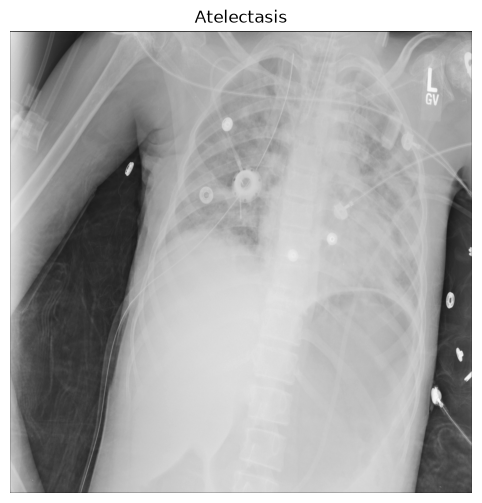

In [34]:
plt.figure(figsize=(6,6))
plt.imshow(image_array, cmap='grey')
plt.title(image_df.iloc[0]["finding_labels"])
plt.axis("off")
plt.show()

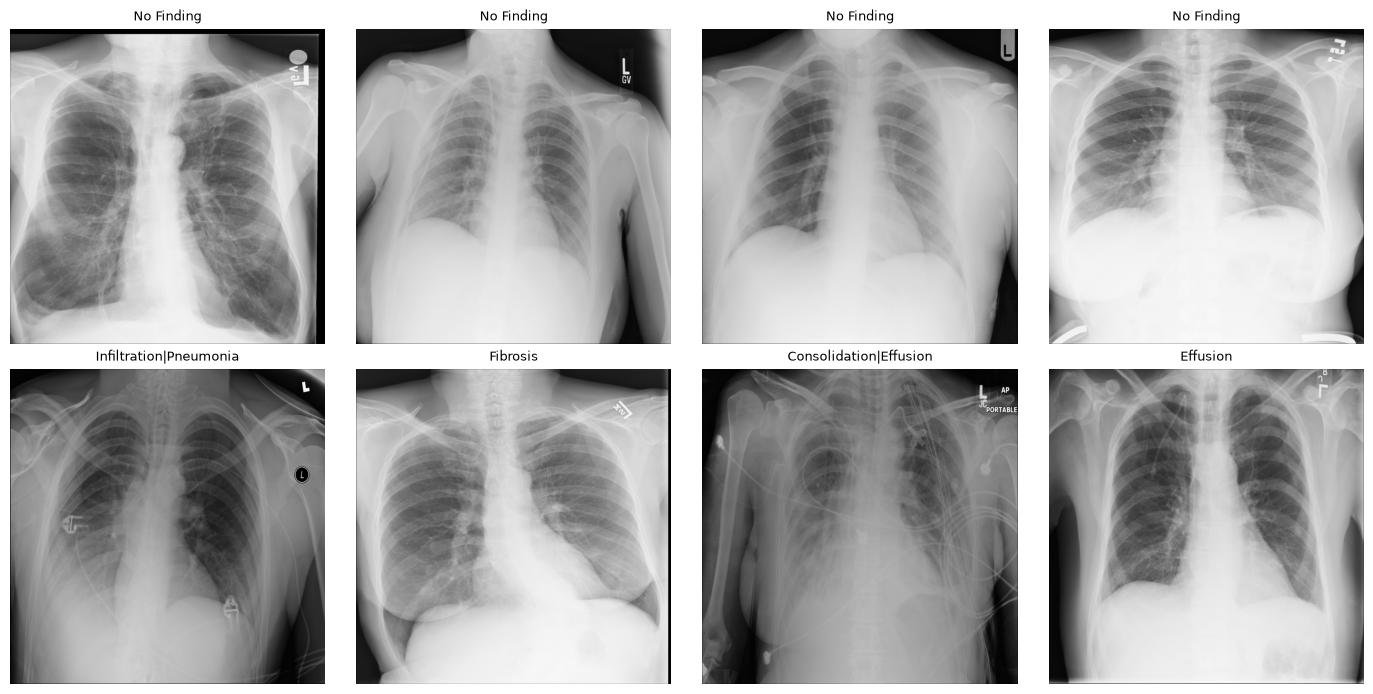

In [35]:
# Compare a small sample of normal and abnormal images before defining preprocessing.
sample_df = pd.concat([
    image_df[image_df["finding_labels"] == "No Finding"].sample(4, random_state=42),
    image_df[image_df["finding_labels"] != "No Finding"].sample(4, random_state=42)
])

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for ax, (_, row) in zip(axes.flat, sample_df.iterrows()):
    image = Image.open(image_dir / row["image_index"])
    ax.imshow(image, cmap="gray")
    ax.set_title(row["finding_labels"], fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

The sampled radiographs show meaningful variation in acquisition and image appearance, including PA and AP projections, differences in positioning and inspiration, variable contrast/exposure, and the presence of portable imaging artifacts such as leads and support devices.

These differences are clinically expected but may also provide non-pathologic cues to a deep learning model. Preprocessing and evaluation should therefore account for acquisition variability rather than assuming all images are visually standardized.

In [ ]:
# Sample image dimensions and intensity statistics to confirm image consistency
# and quantify variation in pixel values before defining preprocessing.

image_stats = []

for path in image_files[:500]:
    image = Image.open(path)
    image_array = np.array(image)

    image_stats.append({
        "image_index": path.name,
        "height": image_array.shape[0],
        "width": image_array.shape[1],
        "min_pixel": image_array.min(),
        "max_pixel": image_array.max(),
        "mean_pixel": image_array.mean()
    })

image_stats_df = pd.DataFrame(image_stats)

image_stats_df.describe()


,height,width,min_pixel,max_pixel,mean_pixel
count,500.0,500.0,500.000000,500.000000,500.000000
mean,1024.0,1024.0,1.978000,242.012000,147.122677
std,0.0,0.0,4.099161,10.978749,18.600721
min,1024.0,1024.0,0.000000,160.000000,92.959126
25%,1024.0,1024.0,0.000000,234.000000,132.598952
50%,1024.0,1024.0,0.000000,242.000000,151.529152
75%,1024.0,1024.0,2.000000,252.000000,161.312595
max,1024.0,1024.0,31.000000,255.000000,194.544664


The sampled chest X-rays were consistently **1024 × 1024 pixels**, indicating that image dimensions are standardized within the downloaded batch.

Pixel intensities, however, varied substantially across images. Mean intensity ranged from approximately **93 to 195**, while maximum pixel values ranged from **160 to 255**. This confirms the visual differences in exposure and contrast observed in the sample images.

The images are therefore spatially consistent but not intensity-standardized. Image resizing and intensity normalization will be important preprocessing steps before model training.

### AP vs PA Projection

AP and PA chest radiographs differ in acquisition geometry, patient positioning, and often clinical context. A small sample of each projection is compared to understand whether projection-related variation should be considered during model development.

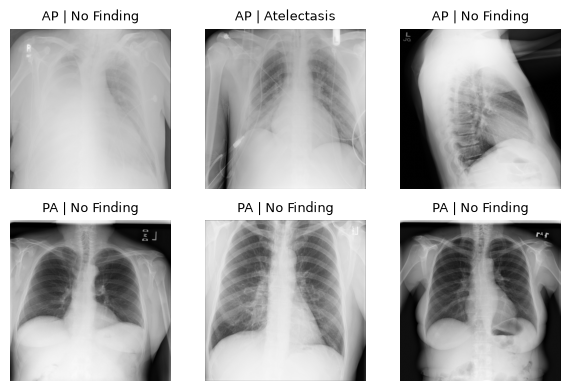

In [39]:
ap_sample = image_df[image_df["view_position"] == "AP"].sample(3, random_state=42)
pa_sample = image_df[image_df["view_position"] == "PA"].sample(3, random_state=42)

projection_sample = pd.concat([ap_sample, pa_sample])

fig, axes = plt.subplots(2,3, figsize=(6,4))

for ax, (_, row) in zip(axes.flat, projection_sample.iterrows()):
    image = Image.open(image_dir / row["image_index"])

    ax.imshow(image, cmap="gray")
    ax.set_title(f'{row['view_position']} | {row['finding_labels']}', fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

AP images show more variability in positioning and image quality than PA images, including poorer inspiration, rotation, and contrast differences in some cases.

This is clinically expected. AP chest radiographs are often obtained when a patient's condition does not allow a standard upright PA examination, such as with portable imaging or limited mobility. As a result, AP images may contain both technical differences and indirect signals of patient acuity.

This matters for modeling because the network could learn projection- or care-setting-related cues in addition to actual pathology. Projection type should therefore be considered during model development and evaluation.

## Exploratory Data Analysis Summary

The NIH ChestX-ray14 metadata contains **112,120 images from 30,805 patients**, with no missing values or duplicate image identifiers in the metadata reviewed. Although the median patient contributes only one image, some patients have more than 100 repeated examinations. Because multiple images may come from the same patient, train, validation, and test sets must be separated at the **patient level** to prevent information leakage.

The dataset is highly imbalanced. More than half of the images are labeled `No Finding`, while several abnormalities occur in fewer than 3% of images. Most images contain a single label, but a substantial number contain multiple abnormalities.

This makes the task a **multi-label classification problem** rather than a standard multiclass problem. The 14 disease labels are not mutually exclusive: one image can be positive for several findings at the same time. The model will therefore need to produce an independent probability for each disease rather than selecting a single class. This will affect the loss function, thresholding strategy, and evaluation metrics, and performance should be assessed by disease label rather than relying on a single overall accuracy value.

Disease labels also show meaningful co-occurrence, with several findings appearing together more frequently than others. This further supports treating the labels as related but non-exclusive outputs.

An important limitation is that the NIH disease labels are **weak labels derived automatically from associated radiology-report text rather than manually verified image-level annotations for every radiograph**. As a result, some labels may be missing, incorrect, or imprecise. Model performance will therefore partly reflect the quality of the label-extraction process rather than only the model's ability to recognize true radiographic findings. This limitation will need to be considered when interpreting both errors and apparent model performance.

Image-level inspection showed that the sampled chest radiographs are consistently **1024 × 1024 grayscale PNGs**, but their intensity distributions and visual appearance vary considerably. Differences were observed in contrast, positioning, inspiration, and acquisition technique.

AP images showed particularly noticeable variability compared with PA images. This is clinically expected because AP radiographs are often used when a patient's condition or mobility prevents a standard upright PA examination. As a result, projection type may contain information about both acquisition technique and patient condition, creating a risk that the model could learn non-pathologic cues in addition to disease features.

Overall, model development will need to account for **patient-level leakage, severe class imbalance, multi-label outputs, weak-label uncertainty, acquisition variability, and image intensity normalization**.